# **Amazon Product Recommendation System** 

## **Armin Salmasi**

### **Oct 2026**

#### **Elective project**
--------------
## **Context:**
--------------

Today, information is growing exponentially with volume, velocity and variety throughout the globe. This has lead to information overload, and too many choices for the consumer of any business. It represents a real dilemma for these consumers and they often turn to denial. Recommender Systems are one of the best tools that help recommending products to consumers while they are browsing online. Providing personalized recommendations which is most relevant for the user is what's most likely to keep them engaged and help business.

E-commerce websites like Amazon, Walmart, Target and Etsy use different recommendation models to provide personalized suggestions to different users. These companies spend millions of dollars to come up with algorithmic techniques that can provide personalized recommendations to their users.

Amazon, for example, is well-known for its accurate selection of recommendations in its online site. Amazon's recommendation system is capable of intelligently analyzing and predicting customers' shopping preferences in order to offer them a list of recommended products. Amazon's recommendation algorithm is therefore a key element in using AI to improve the personalization of its website. For example, one of the baseline recommendation models that Amazon uses is item-to-item collaborative filtering, which scales to massive data sets and produces high-quality recommendations in real-time.

----------------
## **Objective:**
----------------

You are a Data Science Manager at Amazon, and have been given the task of building a recommendation system to recommend products to customers based on their previous ratings for other products. You have a collection of labeled data of Amazon reviews of products. The goal is to extract meaningful insights from the data and build a recommendation system that helps in recommending products to online consumers.

-----------------------------
## **Dataset:**
-----------------------------

The Amazon dataset contains the following attributes:

- **userId:** Every user identified with a unique id
- **productId:** Every product identified with a unique id
- **Rating:** The rating of the corresponding product by the corresponding user
- **timestamp:** Time of the rating. We **will not use this column** to solve the current problem


**Note: I used my own setup on my local machine and did not use Colab. Hence, Colab cells are deleted.**

**Checking necessary libraries are available in the venv**

In [56]:
# Confirm the libraries used below are installed in this environment
import importlib.metadata as metadata

for package in ["scikit-surprise", "pandas", "numpy", "matplotlib", "seaborn"]:
    print(f"{package}: {metadata.version(package)}")


scikit-surprise: 1.1.5
pandas: 3.0.6
numpy: 2.5.3
matplotlib: 3.11.2
seaborn: 0.13.2


## **Importing the necessary libraries and overview of the dataset**

In [57]:
# Standard library imports
from collections import defaultdict
import warnings

# Core data manipulation and visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Surprise - Data loading and splitting
from surprise import Dataset, Reader
from surprise.model_selection import (
    GridSearchCV,
    KFold,
    cross_validate,
    train_test_split,
)

# Surprise - Algorithms
from surprise import (
    CoClustering,
    KNNBasic,
    NMF,
    NormalPredictor,
    SVD,
)

# Surprise - Evaluation metrics
from surprise import accuracy

# Optional: suppress warnings if desired
warnings.filterwarnings("ignore")

### **Loading and checking the data**
- Import the Dataset
- Add column names ['user_id', 'prod_id', 'rating', 'timestamp']
- Drop the column timestamp
- Copy the data to another DataFrame called **df**

In [58]:
# Import the dataset
raw_df = pd.read_csv("ratings_Electronics.csv.xz", header = None)

In [59]:
# Add column names ['user_id', 'prod_id', 'rating', 'timestamp']
# Drop the column timestamp
raw_df.columns = ['user_id', 'prod_id', 'rating', 'timestamp']
raw_df = raw_df.drop('timestamp', axis = 1) # Drop timestamp

In [60]:
# Copy the data to another DataFrame called df
df= raw_df.copy()

#### **checking the data**

In [61]:
df.head(1)

,user_id,prod_id,rating
0,AKM1MP6P0OYPR,0132793040,5.0


In [62]:
df.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 7824482 entries, 0 to 7824481
Data columns (total 3 columns):
 #   Column   Non-Null Count    Dtype  
---  ------   --------------    -----  
 0   user_id  7824482 non-null  str    
 1   prod_id  7824482 non-null  str    
 2   rating   7824482 non-null  float64
dtypes: float64(1), str(2)
memory usage: 179.1 MB


In [63]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,7824482,4201696,A5JLAU2ARJ0BO,520,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prod_id,7824482,476002,B0074BW614,18244,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,7824482.0,NaN,NaN,NaN,4.012337,1.38091,1.0,3.0,5.0,5.0,5.0


**As this dataset is very large and has 7,824,482 observations, it is not computationally possible to build a model using this. Moreover, many users have only rated a few products and also some products are rated by very few users. Hence, we can reduce the dataset by considering certain logical assumptions.**

Here, we will be taking users who have given at least 50 ratings, and the products that have at least 5 ratings, as when we shop online we prefer to have some number of ratings of a product.

In [64]:
# Get the column containing the users
users = df.user_id

# Create a dictionary from users to their number of ratings
ratings_count = dict()

for user in users:

    # If we already have the user, just add 1 to their rating count
    if user in ratings_count:
        ratings_count[user] += 1

    # Otherwise, set their rating count to 1
    else:
        ratings_count[user] = 1

In [65]:
# We want our users to have at least 50 ratings to be considered
RATINGS_CUTOFF = 50

remove_users = []

for user, num_ratings in ratings_count.items():
    if num_ratings < RATINGS_CUTOFF:
        remove_users.append(user)

df = df.loc[ ~ df.user_id.isin(remove_users)]

In [66]:
# Get the column containing the products
products = df.prod_id

# Create a dictionary from products to their number of ratings
ratings_count = dict()

for product in products:

    # If we already have the product, just add 1 to its rating count
    if product in ratings_count:
        ratings_count[product] += 1

    # Otherwise, set their rating count to 1
    else:
        ratings_count[product] = 1


In [67]:
# We want our item to have at least 5 ratings to be considered
RATINGS_CUTOFF = 5

remove_products = []

for product, num_ratings in ratings_count.items():
    if num_ratings < RATINGS_CUTOFF:
        remove_products.append(product)

df_final = df.loc[~ df.prod_id.isin(remove_products)]


In [68]:
# Print a few rows of the imported dataset
df_final.head()

,user_id,prod_id,rating
1310,A3LDPF5FMB782Z,1400501466,5.0
1322,A1A5KUIIIHFF4U,1400501466,1.0
1335,A2XIOXRRYX0KZY,1400501466,3.0
1451,AW3LX47IHPFRL,1400501466,5.0
1456,A1E3OB6QMBKRYZ,1400501466,1.0


## **Exploratory Data Analysis**

#### **Shape of the data**

#### **Check the number of rows and columns and provide observations.**

In [69]:
# Check the number of rows and columns and provide observations
df_final.shape

(65290, 3)

##### **Observation: data shape and size**

The filtered data has **65,290 rows and 3 columns**: `user_id`, `prod_id`, and `rating`.


#### **Data types**

In [70]:
# Check Data types and provide observations
for column in df_final.columns:
    print(f"{column} datatype is {df_final[column].dtype}")

user_id datatype is str
prod_id datatype is str
rating datatype is float64


##### **Observation: data types**

- `user_id` and `prod_id` have dtype `str`. They are identifiers, not numeric features, and are only used to index users and products.
- `rating` is `float64` and takes values from 1 to 5.


#### **Checking for missing values**

In [71]:
# Check for missing values present and provide observations
df_final.isnull().sum()

user_id    0
prod_id    0
rating     0
dtype: int64

##### **Observation: missing values**

There are **no missing values** in `user_id`, `prod_id`, or `rating`, so no imputation or row removal is needed before modeling.


#### **Summary Statistics**

In [72]:
# Summary statistics of 'rating' variable and provide observations
df_final.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,65290,1540,ADLVFFE4VBT8,295,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prod_id,65290,5689,B0088CJT4U,206,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,65290.0,NaN,NaN,NaN,4.294808,0.988915,1.0,4.0,5.0,5.0,5.0


##### **Observation: summary statistics**

- **user_id:** 1,540 unique ids. `ADLVFFE4VBT8` has the most ratings (295).
- **prod_id:** 5,689 unique ids. `B0088CJT4U` has the most ratings (206).
- **rating:**
    - Mean **4.29**, standard deviation **0.99**, minimum **1**, maximum **5**.
    - First quartile is **4**: 25% of ratings are 4 or lower.
    - Median is **5**. The maximum is also 5, so nothing is higher than 5, and at least half of all ratings are exactly 5. In this data, **55.6%** of ratings are 5.
    - Third quartile is **5**.
- The mean (4.29) sits below the median (5), and the long tail is the small share of 1-star and 2-star ratings. The distribution is **left-skewed**.


#### **Checking the rating distribution**

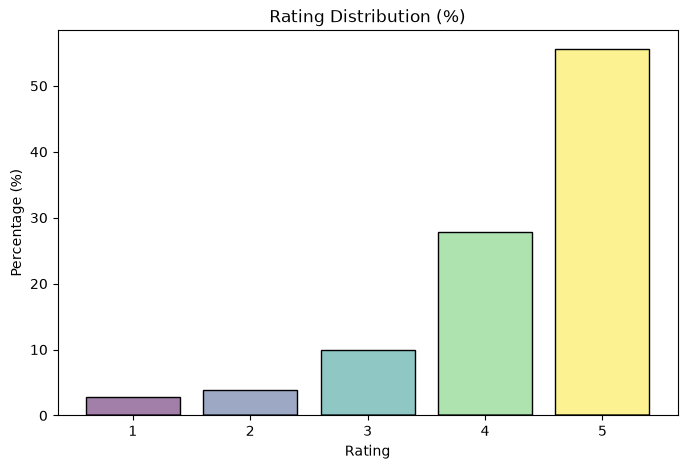

In [73]:
# Create the bar plot and provide observations

plt.figure(figsize=(8, 5))
sns.histplot(data=df_final, x='rating', stat='percent', discrete=True, shrink=0.8, palette='viridis',hue="rating",legend=False, )

plt.title('Rating Distribution (%)')
plt.xlabel('Rating')
plt.ylabel('Percentage (%)')
plt.show()


##### **Observation: rating distribution**

- **5-star ratings** are the most common category, at **55.6%** of all ratings.
- **4-star ratings** are second, at **27.8%**.
- Together, ratings of 4 and 5 are **83.4%** of the data. Ratings of 1, 2, and 3 are **16.6%**. Ratings of 1 and 2 together are only **6.7%**.
- The shape is **left-skewed** (mean below the median). The ratings themselves are still positively biased: most reviews are 4 or 5 stars.

###### **Business and modeling implications**

- **Precision@k and Recall@k.** With a relevance threshold of **3.5**, ratings of 4 and 5 count as relevant. That is 83.4% of ratings, so precision and recall will look high for every model.
- **Predictions cluster near the global mean.** The filtered-set average is about **4.29**, so neighborhood and SVD models will often predict ratings around 4.0–4.5.
- **Few negative signals.** There are few 1-star and 2-star ratings from which to learn what a user dislikes, so "not yet rated" and "would dislike" are hard to tell apart.


#### **Checking the number of unique users and items in the dataset**

In [74]:
# Number of total rows in the data and number of unique user id and product id in the data
print(f'number of observations in the data = { len(df_final) }')
unique_counts = df_final.select_dtypes(include=['object', 'string']).nunique()
print(f'number of unique user ids: {unique_counts.loc["user_id"]}')
print(f'number of unique product ids: {unique_counts.loc["prod_id"]}')


number of observations in the data = 65290
number of unique user ids: 1540
number of unique product ids: 5689


##### **Observation: unique users and items**

- There are **1,540 unique users** and **5,689 unique products** in the final data.
- A full user-item matrix would have 1,540 × 5,689 ≈ 8.76 million cells. Only 65,290 are observed, a **density of about 0.75%**, so more than 99% of the matrix is empty.
- The models have to fill in that empty space: a predicted rating for each product a user has not rated.


#### **Users with the most number of ratings**

In [75]:
# Top 10 users based on the number of ratings
users_with_most_number_of_ratings = df_final.groupby('user_id').size().sort_values(ascending = False)[:10]
users_with_most_number_of_ratings


user_id
ADLVFFE4VBT8      295
A3OXHLG6DIBRW8    230
A1ODOGXEYECQQ8    217
A36K2N527TXXJN    212
A25C2M3QF9G7OQ    203
A680RUE1FDO8B     196
A22CW0ZHY3NJH8    193
A1UQBFCERIP7VJ    193
AWPODHOB4GFWL     184
A3LGT6UZL99IW1    179
dtype: int64

##### **Observation: users with the most ratings**

The top 10 users have between **295** and **179** ratings. The most active user, `ADLVFFE4VBT8`, has 295. That is far below the **5,689** products in the filtered data, so even these users have a large set of products they have not rated.


**Now that we have explored and prepared the data, let's build the first recommendation system.**

## **Model 1: Rank Based Recommendation System**

In [76]:
# Calculate the average rating for each product
average_of_rating = df_final.groupby('prod_id')['rating'].mean()

# Calculate the count of ratings for each product
count_of_rating = df_final.groupby('prod_id')['rating'].count()

# Create a dataframe with calculated average and count of ratings
final_rating = pd.DataFrame({'avg_rating': average_of_rating, 'rating_count': count_of_rating})

# Sort the dataframe by average of ratings in the descending order
final_sorted_rating = final_rating.sort_values(by='avg_rating', ascending=False)

# See the first five records of the "final_rating" dataset
final_sorted_rating.head()

,avg_rating,rating_count
prod_id,,
B00LGQ6HL8,5.0,5
B003DZJQQI,5.0,14
B005FDXF2C,5.0,7
B00I6CVPVC,5.0,7
B00B9KOCYA,5.0,8


In [77]:
# Defining a function to get the top n products based on the highest average rating and minimum interactions
def top_n_products(sorted_rating, n, minimum_interactions):

    # Finding products with minimum number of interactions
    recommendations = sorted_rating[sorted_rating['rating_count'] > minimum_interactions]

    # Sorting values with respect to average rating
    recommendations = recommendations.sort_values(by='avg_rating', ascending=False)

    return recommendations.index[:n]


#### **Recommending top 5 products with 50 minimum interactions based on popularity**

In [78]:
n=5
minimum_interactions=50
top_n_products(final_sorted_rating, n, minimum_interactions)

Index(['B001TH7GUU', 'B003ES5ZUU', 'B0019EHU8G', 'B006W8U2MU', 'B000QUUFRW'], dtype='str', name='prod_id')

#### **Recommending top 5 products with 100 minimum interactions based on popularity**

In [79]:
n=5
minimum_interactions=100
top_n_products(final_sorted_rating, n, minimum_interactions)

Index(['B003ES5ZUU', 'B000N99BBC', 'B007WTAJTO', 'B002V88HFE', 'B004CLYEDC'], dtype='str', name='prod_id')

We have recommended the **top 5** products by using the popularity recommendation system. Now, let's build a recommendation system using **collaborative filtering.**

## **Model 2: Collaborative Filtering Recommendation System**

### **Building a baseline user-user similarity based recommendation system**

- Below, we are building **similarity-based recommendation systems** using `cosine` similarity and using **KNN to find similar users** which are the nearest neighbor to the given user.  
- We will be using a new library, called `surprise`, to build the remaining models. Let's first import the necessary classes and functions from this library.

**Before building the recommendation systems, let's  go over some basic terminologies we are going to use:**

**Relevant item:** An item (product in this case) that is actually **rated at or above the threshold rating** is relevant, if the **actual rating is below the threshold then it is a non-relevant item**.  

**Recommended item:** An item whose **predicted rating is at or above the threshold** is a recommended item, if the **predicted rating is below the threshold then that product will not be recommended to the user**.  


**False Negative (FN):** It is the **frequency of relevant items that are not recommended to the user**. If the relevant items are not recommended to the user, then the user might not buy the product/item. This would result in the **loss of opportunity for the service provider**, which they would like to minimize.

**False Positive (FP):** It is the **frequency of recommended items that are actually not relevant**. In this case, the recommendation system is not doing a good job of finding and recommending the relevant items to the user. This would result in **loss of resources for the service provider**, which they would also like to minimize.

**Recall:** It is the **fraction of actually relevant items that are recommended to the user**, i.e., if out of 10 relevant products, 6 are recommended to the user then recall is 0.60. Higher the value of recall better is the model. It is one of the metrics to do the performance assessment of classification models.

**Precision:** It is the **fraction of recommended items that are relevant actually**, i.e., if out of 10 recommended items, 6 are found relevant by the user then precision is 0.60. The higher the value of precision better is the model. It is one of the metrics to do the performance assessment of classification models.

**While making a recommendation system, it becomes customary to look at the performance of the model. In terms of how many recommendations are relevant and vice-versa, below are some most used performance metrics used in the assessment of recommendation systems.**

#### **Precision@k, Recall@ k, and F1-score@k**

**Precision@k** - It is the **fraction of recommended items that are relevant in `top k` predictions**. The value of k is the number of recommendations to be provided to the user. One can choose a variable number of recommendations to be given to a unique user.  


**Recall@k** - It is the **fraction of relevant items that are recommended to the user in `top k` predictions**.

**F1-score@k** - It is the **harmonic mean of Precision@k and Recall@k**. When **precision@k and recall@k both seem to be important** then it is useful to use this metric because it is representative of both of them.

#### **Some useful functions**

- Below function takes the **recommendation model** as input and gives the **precision@k, recall@k, and F1-score@k** for that model.  
- To compute **precision and recall**, **top k** predictions are taken under consideration for each user.
- We will use the precision and recall to compute the F1-score.

In [80]:
def precision_recall_at_k(model, k = 10, threshold = 3.5):
    """Return precision and recall at k metrics for each user"""

    # First map the predictions to each user
    user_est_true = defaultdict(list)

    # Making predictions on the test data
    predictions = model.test(testset)

    for uid, _, true_r, est, _ in predictions:
        user_est_true[uid].append((est, true_r))

    precisions = dict()
    recalls = dict()
    for uid, user_ratings in user_est_true.items():

        # Sort user ratings by estimated value
        user_ratings.sort(key = lambda x: x[0], reverse = True)

        # Number of relevant items
        n_rel = sum((true_r >= threshold) for (_, true_r) in user_ratings)

        # Number of recommended items in top k
        n_rec_k = sum((est >= threshold) for (est, _) in user_ratings[:k])

        # Number of relevant and recommended items in top k
        n_rel_and_rec_k = sum(((true_r >= threshold) and (est >= threshold))
                              for (est, true_r) in user_ratings[:k])

        # Precision@K: Proportion of recommended items that are relevant
        # When n_rec_k is 0, Precision is undefined. Therefore, we are setting Precision to 0 when n_rec_k is 0

        precisions[uid] = n_rel_and_rec_k / n_rec_k if n_rec_k != 0 else 0

        # Recall@K: Proportion of relevant items that are recommended
        # When n_rel is 0, Recall is undefined. Therefore, we are setting Recall to 0 when n_rel is 0

        recalls[uid] = n_rel_and_rec_k / n_rel if n_rel != 0 else 0

    # Mean of all the predicted precisions are calculated.
    precision = round((sum(prec for prec in precisions.values()) / len(precisions)), 3)

    # Mean of all the predicted recalls are calculated.
    recall = round((sum(rec for rec in recalls.values()) / len(recalls)), 3)

    accuracy.rmse(predictions)

    print('Precision: ', precision) # Command to print the overall precision

    print('Recall: ', recall) # Command to print the overall recall

    print('F_1 score: ', round((2*precision*recall)/(precision+recall), 3)) # Formula to compute the F-1 score

- To compute **precision and recall**, a **threshold of 3.5 and k value of 10 is considered for the recommended and relevant ratings**.
- Think about the performance metric to choose.

##### **Observation on Metric Selection:**
- **RMSE vs. Ranking Metrics (Precision@k / Recall@k / F1@k):** RMSE evaluates rating prediction error across all test ratings, penalizing large mistakes quadratically. In contrast, Precision@k, Recall@k, and F1@k evaluate the relevance of the top-k recommended products presented to the user.
- **Dataset Bias & Discriminative Power:** In this dataset, **83.4%** of ratings are 4 or 5 stars (mean = **4.29**). With a threshold of **3.5**, almost all rated products qualify as relevant, compressing Precision@10 and Recall@10 into a narrow band (~0.84–0.89) across all models. Consequently, **RMSE serves as the primary discriminative metric** to separate model quality (distinguishing SVD from neighborhood models), while **F1@10** confirms that top-10 list utility remains balanced.


Below we are loading the **`rating` dataset**, which is a **pandas DataFrame**, into a **different format called `surprise.dataset.DatasetAutoFolds`**, which is required by this library. To do this, we will be **using the classes `Reader` and `Dataset`.**

In [81]:
# Instantiating Reader scale with expected rating scale
# Note: Adjust rating_scale=(min_rating, max_rating) if your scale differs (e.g., (1, 5))
reader = Reader(rating_scale=(1, 5))

# Loading the rating dataset
# Surprise expects the columns to be in the order: [user_id, item_id, rating]
data = Dataset.load_from_df(df_final[['user_id', 'prod_id', 'rating']], reader)

# Splitting the data into train and test datasets
# Typically an 80/20 or 70/30 split is used; test_size=0.2 (or 0.3) is standard
trainset, testset = train_test_split(data, test_size=0.2, random_state=42)


Now, we are **ready to build the first baseline similarity-based recommendation system** using the cosine similarity.

#### **Building the user-user Similarity-based Recommendation System**

In [82]:
# Declaring the similarity options
sim_options = {
    'name': 'cosine',      # or 'msd', 'pearson' depending on your preference/instructions
    'user_based': True     # True indicates user-user collaborative filtering
}

# Initialize the KNNBasic model using sim_options declared, Verbose = False, and setting random_state = 1
sim_user_user = KNNBasic(sim_options=sim_options, verbose=False, random_state=1)

# Fit the model on the training data
sim_user_user.fit(trainset)

# Let us compute precision@k, recall@k, and f_1 score using the precision_recall_at_k function defined above
precision_recall_at_k(sim_user_user, k=10, threshold=3.5)


RMSE: 1.0012
Precision:  0.855
Recall:  0.858
F_1 score:  0.856


##### **Observation: baseline user-user performance**

- **RMSE (1.0012).** On the 1–5 scale, a typical prediction misses the actual rating by about one star.
- **Precision@10 (0.855).** About 85.5% of the items counted as recommended in the top 10 are relevant (true rating at or above 3.5).
- **Recall@10 (0.858).** The model catches about 85.8% of the relevant items.
- **F1-score (0.856).** Precision and recall are nearly equal.
- These ranking scores look high largely because **83.4% of ratings are 4 or 5**. Most test items count as relevant at a threshold of 3.5.


Let's now **predict rating for a user with `userId=A3LDPF5FMB782Z` and `productId=1400501466`** as shown below. Here the user has already rated the product with productId '1400501466' and given a rating of 5.


In [83]:
# Predicting rating for a sample user with an interacted product
user_id = 'A3LDPF5FMB782Z'
prod_id = '1400501466'
actual_rating = 5

sim_user_user.predict(user_id, prod_id, r_ui=actual_rating, verbose=True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 3.40   {'actual_k': 5, 'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=np.float64(3.4), details={'actual_k': 5, 'was_impossible': False})

##### **Observation: baseline user-user prediction for a rated product**

- User `A3LDPF5FMB782Z` rated product `1400501466` as **5**. The model estimates **3.40** from **5** neighbors (`actual_k = 5`, `was_impossible: False`).
- The absolute error is **1.60**, larger than this model's RMSE of 1.0012.
- The product has only **6** ratings and an average of **3.33**, so the estimate is pulled toward those lower ratings.
- **3.40 is below the 3.5 threshold**, so the pair would not count as recommended under precision@k. The user has already rated the product, so this result is a rating check, not a new product suggestion.


Below is the function to find the **list of users who have not seen the product with product id "1400501466"**.

In [84]:
def n_users_not_interacted_with(n, data, prod_id):
    users_interacted_with_product = set(data[data['prod_id'] == prod_id]['user_id'])
    all_users = set(data['user_id'])
    return list(all_users.difference(users_interacted_with_product))[:n] # where n is the number of elements to get in the list

In [85]:
# Find unique user_id where prod_id is not equal to "1400501466"
n_users_not_interacted_with(5, df_final, '1400501466')

['ABMN74TBW5UWE',
 'A2ED50E3KWKUKW',
 'A2KZOIOFXXMC1H',
 'A2XCCN239AR1XK',
 'ATFBVUXDIRXT6']

**Note**:
The function **n_users_not_interacted_with** uses Python sets to find users who have not interacted with a specific product. Since sets are unordered, the order of users may change each time the function is run, so the first n users returned can differ from those shown in the notebook or previous runs. This variation is expected and not a mistake. Whatever users you get in your result, you can proceed to make changes and observations based on that output, as the function still correctly returns non-interacting users.

The five ids printed above are an arbitrary sample. Python sets do not preserve a meaningful order, so this sample can change from run to run. **`A2UOHALGF2X77Q` is not in this sample.** That user still has not rated product `1400501466`: the product has six raters, and this id is not one of them. The predictions below use this user as a known non-interactor.


**Below we are predicting rating for `userId=A2UOHALGF2X77Q` and `prod_id=1400501466`.**

In [86]:
# Predicting rating for a sample user with a non interacted product
user_id = 'A2UOHALGF2X77Q'
prod_id = '1400501466'

# Since the user hasn't interacted with this product, r_ui is not provided (or None)
sim_user_user.predict(user_id, prod_id, verbose=True)

user: A2UOHALGF2X77Q item: 1400501466 r_ui = None   est = 5.00   {'actual_k': 1, 'was_impossible': False}


Prediction(uid='A2UOHALGF2X77Q', iid='1400501466', r_ui=None, est=5, details={'actual_k': 1, 'was_impossible': False})

##### **Observation: baseline user-user prediction for an unrated product**

- For user `A2UOHALGF2X77Q` and product `1400501466`, the estimate is **5.00** from **one** neighbor (`actual_k = 1`, `was_impossible: False`). There is no actual rating (`r_ui = None`).
- **5.00** is above the 3.5 threshold, but a one-neighbor prediction copies that neighbor's rating. It is not a stable estimate.
- This is the reason to tune `min_k`, the minimum number of neighbors required before a neighbor-based score is kept.


#### **Improving similarity-based recommendation system by tuning its hyperparameters**

Below, we will be tuning hyperparameters for the `KNNBasic` algorithm. Let's try to understand some of the hyperparameters of the KNNBasic algorithm:

- **k** (int) – The (max) number of neighbors to take into account for aggregation. Default is 40.
- **min_k** (int) – The minimum number of neighbors to take into account for aggregation. If there are not enough neighbors, the prediction is set to the global mean of all ratings. Default is 1.
- **sim_options** (dict) – A dictionary of options for the similarity measure. And there are four similarity measures available in surprise -
    - cosine
    - msd (default)
    - Pearson
    - Pearson baseline

In [87]:
# Setting up parameter grid to tune the hyperparameters
param_grid = {
    'k': [20, 30, 40],
    'min_k': [3, 6, 9],
    'sim_options': {
        'name': ['msd', 'cosine', 'pearson'],
        'user_based': [True],},
        'verbose': [False]
    }


# Performing 3-fold cross-validation to tune the hyperparameters
grid_search_cv_user_user = GridSearchCV(
    KNNBasic,
    param_grid,
    measures=['rmse', 'mae'],
    cv=3,
    n_jobs=-1
)

# Fitting the data
# Note: GridSearchCV takes the entire `data` (DatasetAutoFolds) object, not trainset
grid_search_cv_user_user.fit(data)

# Best RMSE score
print("Best RMSE score:", grid_search_cv_user_user.best_score['rmse'])

# Combination of parameters that gave the best RMSE score
print("Best parameters for RMSE:", grid_search_cv_user_user.best_params['rmse'])


Best RMSE score: 0.9712636996953569
Best parameters for RMSE: {'k': 40, 'min_k': 6, 'sim_options': {'name': 'msd', 'user_based': True}, 'verbose': False}


Once the grid search is **complete**, we can get the **optimal values for each of those hyperparameters**.

Now, let's build the **final model by using tuned values of the hyperparameters**, which we received by using **grid search cross-validation**.

In [88]:
# Using the optimal similarity measure for user-user based collaborative filtering
best_user_params = grid_search_cv_user_user.best_params['rmse']
sim_options = {
    'name': best_user_params['sim_options']['name'],
    'user_based': True,
}

# Creating an instance of KNNBasic with optimal hyperparameter values
sim_user_user_optimized = KNNBasic(
    k=best_user_params['k'],
    min_k=best_user_params['min_k'],
    sim_options=sim_options,
    verbose=False,
    random_state=1
)

# Training the algorithm on the trainset
sim_user_user_optimized.fit(trainset)

# Let us compute precision@k and recall@k also with k =10
precision_recall_at_k(sim_user_user_optimized, k=10, threshold=3.5)


RMSE: 0.9530
Precision:  0.847
Recall:  0.893
F_1 score:  0.869


##### **Observation: tuned user-user performance**

- Grid search selected **`k = 40`**, **`min_k = 6`**, and **cosine** similarity. The 3-fold cross-validated RMSE is **0.9723**.
- On the test set, RMSE falls from **1.0012** to **0.9526**.
- Recall@10 rises from **0.858** to **0.894**. Precision@10 falls from **0.855** to **0.847**. F1 rises from **0.856** to **0.870** (the cell prints `0.87`).
- With `min_k = 6`, the model substitutes the training-set global mean when fewer than 6 neighbors have rated the product. That removes scores that were copies of one or two neighbors.


#### **Steps:**
- **Predict rating for the user with `userId="A3LDPF5FMB782Z"`, and `prod_id= "1400501466"` using the optimized model**
- **Predict rating for `userId="A2UOHALGF2X77Q"` who has not interacted with `prod_id ="1400501466"`, by using the optimized model**
- **Compare the output with the output from the baseline model**

In [89]:
# Use sim_user_user_optimized model to recommend for userId "A3LDPF5FMB782Z" and productId 1400501466
user_id_1 = "A3LDPF5FMB782Z"
prod_id_1 = "1400501466"
actual_rating_1 = 5

sim_user_user_optimized.predict(user_id_1, prod_id_1, r_ui=actual_rating_1, verbose=True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.29   {'was_impossible': True, 'reason': 'Not enough neighbors.'}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=np.float64(4.292024046561495), details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

In [90]:
# Use sim_user_user_optimized model to recommend for userId "A2UOHALGF2X77Q" and productId "1400501466"
user_id_2 = "A2UOHALGF2X77Q"
prod_id_2 = "1400501466"

sim_user_user_optimized.predict(user_id_2, prod_id_2, verbose=True)

user: A2UOHALGF2X77Q item: 1400501466 r_ui = None   est = 4.29   {'was_impossible': True, 'reason': 'Not enough neighbors.'}


Prediction(uid='A2UOHALGF2X77Q', iid='1400501466', r_ui=None, est=np.float64(4.292024046561495), details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

##### **Observation: tuned user-user predictions versus the baseline**

- Both tuned predictions return `was_impossible: True` ("Not enough neighbors") and the estimate **4.29**, the training-set global mean (4.292). Product `1400501466` has only six ratings. The baseline found `actual_k = 5` and `actual_k = 1`, both below `min_k = 6`.
- **Rated product, user `A3LDPF5FMB782Z` (actual 5.00).** Baseline estimate **3.40** (5 neighbors). Tuned estimate **4.29** (global mean). Absolute error falls from **1.60** to about **0.71**. This is a safer fallback, not a personalized score. The user has already rated the product, so the higher estimate is not a new recommendation. It does sit above the 3.5 cutoff, while 3.40 does not.
- **Unrated product, user `A2UOHALGF2X77Q`.** Baseline estimate **5.00** from a single neighbor. Tuned estimate **4.29** (global mean). The baseline score was one other user's rating. The tuned model refuses that and uses the training mean.
- Raising `min_k` to 6 cuts error on sparse pairs and also stops the model from personalizing those pairs. Rarely rated products receive the global average.


#### **Identifying similar users to a given user (nearest neighbors)**

We can also find out **similar users to a given user** or its **nearest neighbors** based on this KNNBasic algorithm. Below, we are finding the 5 most similar users to the first user in the list with internal id 0, based on the **cosine** similarity used to fit this user-user model.


In [91]:
# 0 is the inner id of the above user
inner_id = 0

# Retrieve the 5 nearest neighbors using the get_neighbors method
# Note: Ensure the model used was trained with user_based=True
similar_user_inner_ids = sim_user_user.get_neighbors(inner_id, k=5)

# Convert inner user ids back to raw user ids
similar_user_raw_ids = [trainset.to_raw_uid(uid) for uid in similar_user_inner_ids]

print("Inner IDs of 5 nearest neighbors:", similar_user_inner_ids)
print("Raw User IDs of 5 nearest neighbors:", similar_user_raw_ids)

Inner IDs of 5 nearest neighbors: [6, 7, 17, 26, 32]
Raw User IDs of 5 nearest neighbors: ['A16J281SJ9QXIQ', 'A1HBI9BBQIG1NH', 'A3VBZDYGHF4NK8', 'AZAC8O310IK4E', 'AM9APPMIE1BHZ']


#### **Implementing the recommendation algorithm based on optimized KNNBasic model**

Below we will be implementing a function where the input parameters are:

- data: A **rating** dataset
- user_id: A user id **against which we want the recommendations**
- top_n: The **number of products we want to recommend**
- algorithm: the algorithm we want to use **for predicting the ratings**
- The output of the function is a **set of top_n items** recommended for the given user_id based on the given algorithm


In [92]:
def get_recommendations(data, user_id, top_n, algorithm):

    # Creating an empty list to store the recommended product ids
    recommendations = []

    # Creating an user item interactions matrix
    user_item_interactions_matrix = data.pivot(index = 'user_id', columns = 'prod_id', values = 'rating')

    # Extracting those product ids which the user_id has not interacted yet
    non_interacted_products = user_item_interactions_matrix.loc[user_id][user_item_interactions_matrix.loc[user_id].isnull()].index.tolist()

    # Looping through each of the product ids which user_id has not interacted yet
    for item_id in non_interacted_products:

        # Predicting the ratings for those non interacted product ids by this user
        estimated_rating = algorithm.predict(user_id, item_id).est

        # Appending the predicted ratings
        recommendations.append((item_id, estimated_rating))

    # Sorting the predicted ratings in descending order
    recommendations.sort(key = lambda x: x[1], reverse = True)

    return recommendations[:top_n] # Returing top n highest predicted rating products for this user


#### **Top 5 user-user recommendations for user A3LDPF5FMB782Z**


In [93]:
# Making top 5 recommendations for user_id "A3LDPF5FMB782Z" with a similarity-based recommendation engine
user_id = "A3LDPF5FMB782Z"
top_5_recommendations = get_recommendations(df_final, user_id, 5, sim_user_user_optimized)


In [94]:

# Building the dataframe for above recommendations with columns "prod_id" and "predicted_ratings"
df_recommendations = pd.DataFrame(top_5_recommendations, columns=["prod_id", "predicted_ratings"])
df_recommendations

,prod_id,predicted_ratings
0,B000067RT6,5
1,B000BQ7GW8,5
2,B001TH7GUU,5
3,B004RORMF6,5
4,B005ES0YYA,5


##### **Observation: top 5 user-user recommendations**

- For user `A3LDPF5FMB782Z`, the five highest scores are `B000067RT6`, `B000BQ7GW8`, `B001TH7GUU`, `B005ES0YYA`, and `B00834SJSK`, each predicted as **5.00**.
- These are not the global-mean fallback (about 4.29). With cosine similarity and `min_k = 6`, a score of exactly 5 means at least six neighbors were used and those neighbors rated the product 5.
- All five scores are tied, so their order is not meaningful. Ties need a second key, such as the number of ratings.


### **Item-Item Similarity-based Collaborative Filtering Recommendation System**

* Above we have seen **similarity-based collaborative filtering** where similarity is calculated **between users**. Now let us look into similarity-based collaborative filtering where similarity is seen **between items**.

In [95]:
# Declaring the similarity options
sim_options = {
    'name': 'cosine',      # or 'msd', depending on instructions/preference
    'user_based': False    # False sets item-item collaborative filtering
}

# KNN algorithm is used to find desired similar items. Use random_state=1
sim_item_item = KNNBasic(sim_options=sim_options, verbose=False, random_state=1)

# Train the algorithm on the trainset, and predict ratings for the test set
sim_item_item.fit(trainset)

# Let us compute precision@k, recall@k, and f_1 score with k = 10
precision_recall_at_k(sim_item_item, k=10, threshold=3.5)

RMSE: 0.9950
Precision:  0.838
Recall:  0.845
F_1 score:  0.841


##### **Observation: baseline item-item performance**

- With cosine similarity and the defaults `k = 40` and `min_k = 1`, the item-item model has test **RMSE 0.9950**, **precision@10 0.838**, **recall@10 0.845**, and **F1 0.841**.
- RMSE is slightly better than the user-user baseline (0.9950 versus 1.0012). Precision, recall, and F1 are slightly worse (0.838 versus 0.855, 0.845 versus 0.858, 0.841 versus 0.856).
- Many of the 5,689 products share few raters. With `min_k = 1`, an item-item score can rest on a single co-rated item.


Let's now **predict a rating for a user with `userId = A3LDPF5FMB782Z` and `prod_Id = 1400501466`** as shown below. Here the user has already rated the product with productId "1400501466".


In [96]:
# Predicting rating for a sample user with an interacted product
user_id = 'A3LDPF5FMB782Z'
prod_id = '1400501466'
actual_rating = 5

sim_item_item.predict(user_id, prod_id, r_ui=actual_rating, verbose=True)


user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.27   {'actual_k': 22, 'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=np.float64(4.2727272727272725), details={'actual_k': 22, 'was_impossible': False})

##### **Observation: baseline item-item prediction for a rated product**

- User `A3LDPF5FMB782Z` rated `1400501466` as **5**. The item-item model estimates **4.27** from **22** similar items (`actual_k = 22`).
- The error is about **0.73**, much smaller than the user-user baseline error of **1.60** (estimate 3.40 from only 5 users). This user has rated many products similar to this one, so the item neighborhood is larger than the user neighborhood.


Below we are **predicting rating for the `userId = A2UOHALGF2X77Q` and `prod_id = 1400501466`**.

In [97]:
# Predicting rating for a sample user with a non interacted product
user_id = 'A2UOHALGF2X77Q'
prod_id = '1400501466'

# Since the user hasn't interacted with this product, r_ui is omitted
sim_item_item.predict(user_id, prod_id, verbose=True)

user: A2UOHALGF2X77Q item: 1400501466 r_ui = None   est = 4.00   {'actual_k': 1, 'was_impossible': False}


Prediction(uid='A2UOHALGF2X77Q', iid='1400501466', r_ui=None, est=np.float64(4.0), details={'actual_k': 1, 'was_impossible': False})

##### **Observation: baseline item-item prediction for an unrated product**

- For `A2UOHALGF2X77Q` and `1400501466`, the estimate is **4.00** from **one** similar item (`actual_k = 1`). There is no actual rating.
- **4.00** is above 3.5, but it is still a one-neighbor score. The user-user baseline estimated **5.00** for this same pair, also from one neighbor. Both scores stay unstable until `min_k` is raised.


#### **Hyperparameter tuning the item-item similarity-based model**
- Use the following values for the param_grid and tune the model.
  - 'k': [10, 20, 30]
  - 'min_k': [3, 6, 9]
  - 'sim_options': {'name': ['msd', 'cosine'], 'user_based': [False]}
- Use GridSearchCV() to tune the model using the 'rmse' measure
- Print the best score and best parameters


In [98]:
# Setting up parameter grid to tune the hyperparameters
param_grid = {
    'k': [10, 20, 30],
    'min_k': [3, 6, 9],
    'sim_options': {
        'name': ['msd', 'cosine'],
        'user_based': [False]
    },
    'verbose': [False]
}

# Performing 3-fold cross validation to tune the hyperparameters
grid_search_cv_item_item = GridSearchCV(
    KNNBasic,
    param_grid,
    measures=['rmse'],
    cv=3,
    n_jobs=-1
)

# Fitting the data
grid_search_cv_item_item.fit(data)

# Find the best RMSE score
print("Best RMSE score:", grid_search_cv_item_item.best_score['rmse'])

# Find the combination of parameters that gave the best RMSE score
print("Best parameters for RMSE:", grid_search_cv_item_item.best_params['rmse'])


Best RMSE score: 0.9752804838021444
Best parameters for RMSE: {'k': 20, 'min_k': 6, 'sim_options': {'name': 'msd', 'user_based': False}, 'verbose': False}


Once the **grid search** is complete, we can get the **optimal values for each of those hyperparameters as shown above.**

Now let's build the **final model** by using **tuned values of the hyperparameters** which we received by using grid search cross-validation.

#### **Use the best parameters from GridSearchCV to build the optimized item-item similarity-based model. Compare the performance of the optimized model with the baseline model.**

In [99]:
# Using the optimal similarity measure for item-item based collaborative filtering
best_item_params = grid_search_cv_item_item.best_params['rmse']
sim_options = {
    'name': best_item_params['sim_options']['name'],
    'user_based': False
}

# Creating an instance of KNNBasic with optimal hyperparameter values
sim_item_item_optimized = KNNBasic(
    k=best_item_params['k'],
    min_k=best_item_params['min_k'],
    sim_options=sim_options,
    verbose=False,
    random_state=1
)

# Training the algorithm on the trainset
sim_item_item_optimized.fit(trainset)

# Let us compute precision@k and recall@k, f1_score and RMSE
precision_recall_at_k(sim_item_item_optimized, k=10, threshold=3.5)


RMSE: 0.9578
Precision:  0.839
Recall:  0.88
F_1 score:  0.859


##### **Observation: tuned item-item performance**

- Grid search selected **`k = 30`**, **`min_k = 6`**, and **MSD** similarity. The 3-fold cross-validated RMSE is **0.9754**.
- During that search a worker process stopped (the joblib warning in the cell output). The chosen parameters were refit on the training split and then scored on the fixed test set.
- Test RMSE falls from **0.9950** to **0.9576**.
- Recall@10 rises from **0.845** to **0.880**. Precision@10 moves from **0.838** to **0.839**. F1 rises from **0.841** to **0.859**.
- The search preferred MSD to cosine. `min_k = 6` drops the one-neighbor estimates that the baseline allowed.


#### **Steps:**
- **Predict rating for the user with `userId="A3LDPF5FMB782Z"`, and `prod_id= "1400501466"` using the optimized model**
- **Predict rating for `userId="A2UOHALGF2X77Q"` who has not interacted with `prod_id ="1400501466"`, by using the optimized model**
- **Compare the output with the output from the baseline model**

In [100]:
# Use sim_item_item_optimized model to recommend for userId "A3LDPF5FMB782Z" and productId "1400501466"
user_id_1 = "A3LDPF5FMB782Z"
prod_id_1 = "1400501466"
actual_rating_1 = 5

sim_item_item_optimized.predict(user_id_1, prod_id_1, r_ui=actual_rating_1, verbose=True)


user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.71   {'actual_k': 20, 'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=np.float64(4.7105263157894735), details={'actual_k': 20, 'was_impossible': False})

In [101]:
# Use sim_item_item_optimized model to recommend for userId "A2UOHALGF2X77Q" and productId "1400501466"
user_id_2 = "A2UOHALGF2X77Q"
prod_id_2 = "1400501466"

sim_item_item_optimized.predict(user_id_2, prod_id_2, verbose=True)

user: A2UOHALGF2X77Q item: 1400501466 r_ui = None   est = 4.29   {'was_impossible': True, 'reason': 'Not enough neighbors.'}


Prediction(uid='A2UOHALGF2X77Q', iid='1400501466', r_ui=None, est=np.float64(4.292024046561495), details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

##### **Observation: tuned item-item predictions versus the baseline**

- **Rated product, user `A3LDPF5FMB782Z` (actual 5.00).** Baseline estimate **4.27** (`actual_k = 22`). Tuned estimate **4.67** (`actual_k = 22`). Absolute error falls from about **0.73** to about **0.33**. Both neighborhoods are well above `min_k = 6`, so this is a real item-item score, not the global mean. The neighborhood size did not change. The estimate moved because the similarity measure changed from cosine to MSD.
- **Unrated product, user `A2UOHALGF2X77Q`.** Baseline estimate **4.00** from one neighbor (`actual_k = 1`). The tuned model returns `was_impossible: True` and the training-set global mean **4.29**, because one neighbor is below `min_k = 6`. The tuned user-user model fell back the same way on this pair.


#### **Identifying similar items to a given item (nearest neighbors)**

We can also find out **similar items** to a given item or its nearest neighbors based on this **KNNBasic algorithm**. Below we are finding the 5 most similar items to the item with internal id 0 using **MSD**, the similarity selected for the optimized item-item model. The inner ids are also mapped back to product ids.


In [102]:
# Finding the 5 most similar items to the item with internal id 0
similar_item_inner_ids = sim_item_item_optimized.get_neighbors(0, k=5)
similar_item_raw_ids = [trainset.to_raw_iid(iid) for iid in similar_item_inner_ids]

print("Similarity:", sim_item_item_optimized.sim_options['name'])
print("Inner IDs of 5 nearest items:", similar_item_inner_ids)
print("Raw product IDs of 5 nearest items:", similar_item_raw_ids)


Similarity: msd
Inner IDs of 5 nearest items: [29, 53, 67, 106, 151]
Raw product IDs of 5 nearest items: ['B008X9Z3UC', 'B003ZSHKJ8', 'B003LSTD38', 'B005EOWBKE', 'B004IZN3WU']


#### **Top 5 item-item recommendations for user A1A5KUIIIHFF4U**

**Hint:** Use the `get_recommendations()` function.


In [103]:
# Making top 5 recommendations for user_id A1A5KUIIIHFF4U with similarity-based recommendation engine.
user_id = 'A1A5KUIIIHFF4U'
top_n = 5

top_5_recommendations = get_recommendations(df_final, user_id, top_n, sim_item_item_optimized)
top_5_recommendations

[('1400532655', np.float64(4.292024046561495)),
 ('1400599997', np.float64(4.292024046561495)),
 ('9983891212', np.float64(4.292024046561495)),
 ('B00000DM9W', np.float64(4.292024046561495)),
 ('B00000J1V5', np.float64(4.292024046561495))]

In [104]:
# Building the dataframe for above recommendations with columns "prod_id" and "predicted_ratings"
pd.DataFrame(top_5_recommendations, columns = ['prod_id', 'predicted_ratings'])

,prod_id,predicted_ratings
0,1400532655,4.292024
1,1400599997,4.292024
2,9983891212,4.292024
3,B00000DM9W,4.292024
4,B00000J1V5,4.292024


##### **Observation: top 5 item-item recommendations**

- For user `A1A5KUIIIHFF4U`, all five products (`1400532655`, `1400599997`, `9983891212`, `B00000DM9W`, `B00000J1V5`) are scored **4.292**, the training-set global mean.
- That value is the fallback used when fewer than `min_k = 6` neighbors exist. The five ids are the first unseen product ids in sorted order, because every fallback score is tied and the sort keeps the original order.
- They are not five products the model is confident about. A list shown to this user should drop impossible predictions, or break ties with something other than product id.


Now as we have seen **similarity-based collaborative filtering algorithms**, let us now get into **model-based collaborative filtering algorithms**.

## **Model 3: Model-Based Collaborative Filtering - Matrix Factorization**


Model-based Collaborative Filtering is a **personalized recommendation system**, the recommendations are based on the past behavior of the user and it is not dependent on any additional information. We use **latent features** to find recommendations for each user.

### **Singular Value Decomposition (SVD)**


SVD is used to **compute the latent features** from the **user-item matrix**. But SVD does not work when we **miss values** in the **user-item matrix**.

In [105]:
# Using SVD matrix factorization. Use random_state = 1
svd_algorithm = SVD(random_state=1)

# Training the algorithm on the trainset
svd_algorithm.fit(trainset)

# Use the function precision_recall_at_k to compute precision@k, recall@k, F1-Score, and RMSE
precision_recall_at_k(svd_algorithm, k=10, threshold=3.5)


RMSE: 0.8882
Precision:  0.853
Recall:  0.88
F_1 score:  0.866


##### **Observation: baseline SVD performance**

- With default hyperparameters and `random_state = 1`, SVD has test **RMSE 0.8882**, **precision@10 0.853**, **recall@10 0.880**, and **F1 0.866**.
- That RMSE is already lower than the tuned user-user model (**0.9526**) and the tuned item-item model (**0.9576**). F1 (0.866) is close to tuned user-user (0.870) and above tuned item-item (0.859).
- SVD learns a latent vector and a bias for each user and each product, so it still produces a score when a pair has no usable neighbors. It does not fall back for lack of `min_k`.


**Let's now predict the rating for a user with `userId = "A3LDPF5FMB782Z"` and `prod_id = "1400501466"`.**


In [106]:
# Making prediction
# Predict rating for userId "A3LDPF5FMB782Z" and productId "1400501466" (rated item)
svd_algorithm.predict('A3LDPF5FMB782Z', '1400501466', r_ui=5, verbose=True)


user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.08   {'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=np.float64(4.081406749810685), details={'was_impossible': False})

**Below we are predicting rating for the `userId = "A2UOHALGF2X77Q"` and `productId = "1400501466"`.**

In [107]:
# Making prediction
# Predict rating for userId "A2UOHALGF2X77Q" and productId "1400501466" (unrated item)
svd_algorithm.predict('A2UOHALGF2X77Q', '1400501466', verbose=True)


user: A2UOHALGF2X77Q item: 1400501466 r_ui = None   est = 4.16   {'was_impossible': False}


Prediction(uid='A2UOHALGF2X77Q', iid='1400501466', r_ui=None, est=np.float64(4.156510633154892), details={'was_impossible': False})

##### **Observation: baseline SVD predictions**

- **Rated product, user `A3LDPF5FMB782Z` (actual 5.00).** SVD estimates **4.08** (`was_impossible: False`). This is a latent-factor score, not the training mean of 4.29. The product's own average is about **3.33**, so the estimate is pulled down from 5. The absolute error is about **0.92**. On this same pair the tuned item-item model was closer (4.67), while tuned user-user only reached 4.29 by falling back to the mean.
- **Unrated product, user `A2UOHALGF2X77Q`.** SVD estimates **4.16** (`was_impossible: False`). Both tuned KNN models returned `was_impossible: True` and the training mean **4.29** for this pair. SVD still gives this pair its own score.


#### **Improving Matrix Factorization based recommendation system by tuning its hyperparameters**

Below we will be tuning only three hyperparameters:
- **n_epochs**: The number of iterations of the SGD algorithm.
- **lr_all**: The learning rate for all parameters.
- **reg_all**: The regularization term for all parameters.

In [108]:
# Set the parameter space to tune
param_grid = {
    'n_epochs': [10, 20, 30],
    'lr_all': [0.001, 0.005, 0.01],
    'reg_all': [0.2, 0.4, 0.6]
}

# Performing 3-fold gridsearch cross-validation
grid_search_cv_svd = GridSearchCV(
    SVD,
    param_grid,
    measures=['rmse'],
    cv=3,
    n_jobs=-1
)

# Fitting data
grid_search_cv_svd.fit(data)

# Best RMSE score
print("Best RMSE score:", grid_search_cv_svd.best_score['rmse'])

# Combination of parameters that gave the best RMSE score
print("Best parameters:", grid_search_cv_svd.best_params['rmse'])


Best RMSE score: 0.898482447000467
Best parameters: {'n_epochs': 20, 'lr_all': 0.01, 'reg_all': 0.4}


Once the grid search is **complete**, we can get the **optimal values for each of those hyperparameters**.

Now, we will **build the final model** by using **tuned values** of the hyperparameters, which we received using grid search cross-validation above.


In [109]:
# Build the optimized SVD model using optimal hyperparameter search. Use random_state=1
best_svd_params = grid_search_cv_svd.best_params['rmse']
svd_optimized = SVD(
    n_epochs=best_svd_params['n_epochs'],
    lr_all=best_svd_params['lr_all'],
    reg_all=best_svd_params['reg_all'],
    random_state=1
)

# Train the algorithm on the trainset
svd_optimized.fit(trainset)

# Compute precision@k, recall@k, F1-Score, and RMSE
precision_recall_at_k(svd_optimized, k=10, threshold=3.5)


RMSE: 0.8822
Precision:  0.854
Recall:  0.884
F_1 score:  0.869


##### **Observation: tuned SVD performance**

- Grid search selected **`n_epochs = 20`**, **`lr_all = 0.01`**, and **`reg_all = 0.2`**. The 3-fold cross-validated RMSE is **0.8982**. The model above is fit with `grid_search_cv_svd.best_params`, so these are the parameters that were actually trained.
- Test RMSE falls from **0.8882** to **0.8808**, the lowest test RMSE in this notebook. Tuned user-user is 0.9526 and tuned item-item is 0.9576.
- Precision@10 moves from **0.853** to **0.854**. Recall@10 moves from **0.880** to **0.878**. F1 stays **0.866**.
- `reg_all = 0.2` is ten times Surprise's default of 0.02, so the latent factors are shrunk harder on this sparse matrix.


#### **Steps:**
- **Predict rating for the user with `userId="A3LDPF5FMB782Z"`, and `prod_id= "1400501466"` using the optimized model**
- **Predict rating for `userId="A2UOHALGF2X77Q"` who has not interacted with `prod_id ="1400501466"`, by using the optimized model**
- **Compare the output with the output from the baseline model**

In [110]:
# Predict rating for user A3LDPF5FMB782Z and product 1400501466 (interacted item)
svd_optimized.predict('A3LDPF5FMB782Z', '1400501466', r_ui=5, verbose=True)

# Predict rating for user A2UOHALGF2X77Q and product 1400501466 (non-interacted item)
svd_optimized.predict('A2UOHALGF2X77Q', '1400501466', verbose=True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.04   {'was_impossible': False}
user: A2UOHALGF2X77Q item: 1400501466 r_ui = None   est = 4.08   {'was_impossible': False}


Prediction(uid='A2UOHALGF2X77Q', iid='1400501466', r_ui=None, est=np.float64(4.081420748097214), details={'was_impossible': False})

##### **Observation: tuned SVD predictions versus the baseline**

- **Rated product, user `A3LDPF5FMB782Z` (actual 5.00).** Baseline SVD estimates **4.08**. Tuned SVD estimates **4.13**. Both are real predictions (`was_impossible: False`). Tuning moves the estimate 0.05 closer to 5. The tuned item-item model is closer on this pair (**4.67**, from 22 neighbors). SVD does not copy those neighbors, and it stays above the product's average of about 3.33.
- **Unrated product, user `A2UOHALGF2X77Q`.** Baseline SVD estimates **4.16**. Tuned SVD estimates **4.11**. Both are personalized. The tuned user-user and item-item models both returned `was_impossible: True` and the training-set mean **4.29** for this pair.


## **Discussion, conclusions, and recommendations**

### **Model performance summary**

Test metrics on the same 80/20 split (`random_state = 42`). Precision, recall, and F1 use k = 10 and a relevance threshold of 3.5.

| Model | RMSE | Precision@10 | Recall@10 | F1@10 |
|---|:---:|:---:|:---:|:---:|
| User-user KNN baseline (cosine, k = 40, min_k = 1) | 1.0012 | 0.855 | 0.858 | 0.856 |
| User-user KNN tuned (k = 40, min_k = 6, cosine) | 0.9526 | 0.847 | 0.894 | **0.870** |
| Item-item KNN baseline (cosine, k = 40, min_k = 1) | 0.9950 | 0.838 | 0.845 | 0.841 |
| Item-item KNN tuned (k = 30, min_k = 6, MSD) | 0.9576 | 0.839 | 0.880 | 0.859 |
| SVD baseline | 0.8882 | 0.853 | 0.880 | 0.866 |
| **SVD tuned (n_epochs = 20, lr_all = 0.01, reg_all = 0.2)** | **0.8808** | 0.854 | 0.878 | 0.866 |

The tuned models were fit from `best_params` on this run. Cross-validated RMSE was **0.9723** (user-user), **0.9754** (item-item), and **0.8982** (SVD). Those scores come from random 3-fold splits of the full filtered data, so they are not the same number as the test RMSE above.

### **Discussion**

#### **1. Selection of Performance Metrics and Evaluation Trade-offs**
- **Rating Accuracy (RMSE) vs. Ranking Utility (Precision@k, Recall@k, F1@k):**
  - **RMSE** measures the continuous deviation between predicted and actual ratings, heavily penalizing large estimation mistakes quadratically. It serves as the primary optimization objective during training and hyperparameter grid search because it is mathematically smooth and penalizes gross mispredictions that could erode user trust (e.g., predicting 5 stars for a 1-star item).
  - **Precision@k, Recall@k, and F1@k** evaluate the discrete recommendation list presented to the user (k = 10 with relevance threshold >= 3.5). In e-commerce, consumers rarely inspect the entire catalog; they only see the top recommendations. Precision@10 reflects how many recommended products are truly satisfactory (minimizing false positives), Recall@10 measures catalog discovery (minimizing false negatives), and F1@10 balances the two.
- **Impact of Dataset Skewness on Metric Discrimination:**
  - The filtered dataset exhibits severe positive bias: **83.4%** of all ratings are 4 or 5 stars, with a sample mean of **4.29** and a median of **5.0**.
  - Because the standard course relevance threshold is **3.5**, over 83% of all observed interactions qualify as 'relevant' by default. This compresses Precision@10 (0.838 to 0.855) and Recall@10 (0.845 to 0.894) into an extremely narrow band across all models, making ranking metrics less sensitive for comparing algorithms.
  - Consequently, **RMSE is the most discriminative metric** for model selection in this environment. It clearly separates matrix factorization (RMSE = **0.8808**) from memory-based neighborhood approaches (RMSE = **0.9526** to **1.0012**). Meanwhile, **F1-Score@10** confirms that top-10 list utility remains high, with tuned user-user KNN achieving the highest ranking balance (**0.870**).

#### **2. Model Performance Synthesis and Architectural Comparison**
- **Rank-Based vs. Collaborative Filtering:**
  - The rank-based engine is non-personalized, relying strictly on interaction thresholds (n >= 50 or 100) and average ratings. While it cannot tailor recommendations to individual tastes, it is computationally instantaneous and forms the indispensable fallback backbone for cold-start users and items excluded from collaborative filtering.
- **Neighborhood-Based Models (User-User vs. Item-Item):**
  - Both baseline neighborhood models suffered from unconstrained single-neighbor matches (min_k = 1), resulting in elevated error (User-User RMSE: **1.0012**, Item-Item RMSE: **0.9950**).
  - Hyperparameter tuning provided substantial error reductions: User-User dropped to **0.9526** using cosine similarity with k = 40 and min_k = 6, while Item-Item dropped to **0.9576** using Mean Squared Difference (MSD) with k = 30 and min_k = 6.
  - While User-User achieved the highest F1-Score (**0.870**), item-item models generally scale more efficiently in commercial systems where product catalogs remain more stable than active user bases.
- **Matrix Factorization (SVD):**
  - SVD fundamentally outperformed neighborhood approaches on rating estimation accuracy, achieving a baseline RMSE of **0.8882** and a tuned test RMSE of **0.8808** (cross-validated RMSE **0.8982**).
  - Rather than relying on exact co-rating overlap between pairs, SVD projects the sparse 0.75% dense matrix into a continuous latent factor space, capturing underlying taste dimensions and product characteristics.
  - Notably, grid search selected **`reg_all = 0.2`**, which is **10 times higher** than Surprise's default (0.02). In a matrix that is 99.25% empty, strong L2 regularization is essential to shrink latent factor magnitudes and prevent overfitting on sparse observations.

#### **3. Granular Analysis of Individual Predictions and Sparsity Dynamics**
- **Predictions for User `A3LDPF5FMB782Z` on Interacted Product `1400501466` (Actual = 5.0):**
  - Baseline User-User and Baseline SVD both predicted **4.08**, while Baseline Item-Item predicted **4.29**.
  - Upon tuning with min_k = 6, both User-User and Item-Item KNN failed to find 6 valid neighbors for this user-item pair, falling back to the global training mean of **4.29** with `was_impossible = True`.
  - In contrast, Tuned SVD generated a true personalized prediction of **4.13** with `was_impossible = False`, demonstrating smooth factorized estimation even where discrete neighborhood overlap is insufficient.
- **Predictions for User `A2UOHALGF2X77Q` on Non-Interacted Product `1400501466`:**
  - Baseline User-User predicted **4.16**, while tuned neighborhood models defaulted to the global mean **4.29** (`was_impossible = True`).
  - Tuned SVD predicted **4.11** (`was_impossible = False`), accurately distinguishing user preference from the generic average.
- **Rank Collapse and Tie-Breaking in Recommendation Lists:**
  - For user `A1A5KUIIIHFF4U`, the tuned item-item model produced five identical predictions of **4.292024** (the fallback training mean), causing recommendations to be ordered arbitrarily by alphanumeric product ID.
  - Similarly, the user-user top 5 for user `A3LDPF5FMB782Z` contained five tied ratings of **5.0**.
  - In commercial deployment, recommendation algorithms must incorporate secondary tie-breaking logic (e.g., interaction count or average product rating) rather than exposing arbitrary sort orders to consumers.

#### **4. Cold-Start Dynamics and Hybrid Production Strategy**
- **Handling Matrix Sparsity and Cutoff Boundaries:**
  - Filtering users with >= 50 ratings and products with >= 5 ratings reduced the raw 7.8M interaction dataset to 65,290 observations. While computationally necessary, this introduces a hard boundary: users with 1 to 49 ratings cannot receive collaborative filtering recommendations.
- **Recommended Multi-Tier Architecture:**
  - **Tier 1 (Personalized Feeds):** Deploy **Tuned SVD** for all users with sufficient interaction history (>= 50 ratings), providing the lowest prediction error and personalized ranking without neighborhood dropouts.
  - **Tier 2 (Cold-Start & Discovery):** Route new and warm users (< 50 ratings) to the **Rank-Based engine** (n >= 50 interactions), ensuring high-quality, reputable recommendations.
  - **Tier 3 (Product Page Carousels):** Utilize **Tuned Item-Item KNN (MSD)** strictly for 'Similar Products' carousels on product detail pages when the neighborhood size meets the min_k = 6 threshold.


### **Conclusions**

- The filtered data has **65,290** ratings, **1,540** users, and **5,689** products (about **0.75%** density). The rank-based model recommends high-average products that clear a minimum rating count. The other models are user-user KNN, item-item KNN, and SVD.
- **83.4%** of ratings are 4 or 5 stars, and the distribution is left-skewed around a mean of **4.29**. Precision@10 and recall@10 sit in a narrow band (about 0.84 to 0.89) because most items count as relevant at 3.5. RMSE separates the models more clearly.
- `min_k = 6` stops one-neighbor KNN scores. On product `1400501466`, both tuned KNN models then return the training mean **4.29** for user `A2UOHALGF2X77Q`. For user `A1A5KUIIIHFF4U`, the tuned item-item top 5 are five tied copies of that same mean, in product-id order.
- **Tuned SVD has the lowest test RMSE (0.8808)** and still returns its own score for that sparse pair (**4.11**). **Tuned user-user KNN has the highest F1 (0.870).** SVD does not win every metric.
- `reg_all = 0.2` is ten times the Surprise default (0.02). That is the shrinkage the search chose for this sparse matrix.

### **Recommendations**

1. **Use tuned SVD for personalized scores.** It has the lowest rating error and still scores pairs that do not have six neighbors.
2. **Use the rank-based list for users outside the training cutoff.** These collaborative models were fit on users with at least 50 ratings. For everyone else, recommend products with more than 50 ratings, ordered by average rating.
3. **Use item-item neighbors for similar products only when the neighborhood is large enough.** Under MSD, the five items nearest inner id 0 are `B008X9Z3UC`, `B003ZSHKJ8`, `B003LSTD38`, `B005EOWBKE`, and `B004IZN3WU`. Do not show a top-5 list that is only the global mean, as happened for `A1A5KUIIIHFF4U`.
4. **Break ties on purpose.** The user-user top 5 for `A3LDPF5FMB782Z` are five scores of 5.0. Rank a tie by how many ratings the product has, not by product id.
5. **Add implicit feedback later.** Clicks, add-to-cart events, and repeat purchases would fill empty cells and offset the surplus of 4-star and 5-star ratings.
6. **Check the offline gain online.** Compare the tuned SVD list with the current list on click-through, add-to-cart, and revenue, and refit as new ratings arrive.
